# Hybrid search and incremental selection

The search runs in stages, always on temporal validation:

1. **Standalone bases** from several families (statistical, linear, kernel, tree, neural).
2. **Retention:** the two best of each family, ARIMA and the overall best base.
3. **Residual hybrids:** `ŷ = base + α · corrector(residuals)`, with Linear, KNN and MLP correctors, windows of 7 or 28 residuals and `α ∈ {0.5, 1}`.
4. **Refinement** of the two best residual structures.
5. **Incremental selection:** each family challenges the current champion and replaces it only with a median gain ≥ 5% and wins on ≥ 60% of the origins (calibrated rule, ADR-0008).

`quickstart` profile: the protocol's variability criterion is off, and the report says so. The `research_strict` profile requires that criterion to be set.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Data and experiment

ARIMA with automatic order is the most expensive model; here it appears only in the manual examples of section 3, and the automatic search uses the other models.

`budget` limits the **number** of candidates (total, per family and per stage; `max_trials` replaces the total), so the same series and the same seed give the same search on any machine. A wall-clock deadline is optional (`max_wall_time_s=...`): no candidate starts after it, and the ones left out show up in the ledger as `STOPPED`.

In [2]:
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

y = get_data("synthetic_daily")

exp = AutoHybridExperiment(
    fh=14,
    session_id=42,
    fold=3,
    fold_strategy="expanding",
    seasonal_period=7,
    profile="quickstart",
    base_models=["naive", "seasonal_naive", "linear", "knn", "mlp"],
    correctors=["linear", "knn", "mlp"],
    residual_windows=[7, 28],
    residual_sources=["historical_oof_1step"],
    alphas=[0.5, 1.0],
    budget="small",
    max_trials=40,
).fit(y)
exp.splits

,layer,train_start,origin,first_target,last_target,n_train,horizon
fold_id,,,,,,,
search-0,search,2024-01-01,2025-09-23,2025-09-24,2025-10-07,632,14
search-1,search,2024-01-01,2025-10-07,2025-10-08,2025-10-21,646,14
search-2,search,2024-01-01,2025-10-21,2025-10-22,2025-11-04,660,14
select-0,select,2024-01-01,2025-11-04,2025-11-05,2025-11-18,674,14
select-1,select,2024-01-01,2025-11-18,2025-11-19,2025-12-02,688,14
select-2,select,2024-01-01,2025-12-02,2025-12-03,2025-12-16,702,14


## 2. Model catalogue

In [3]:
exp.models()

family  multi_step  \
kind      name                                                       
base      adaboost_r2                             tree        True   
          adida                           intermittent        True   
          arima                            statistical        True   
          catboost_regressor                      tree        True   
          croston_sba                     intermittent        True   
          elastic_net_regression                linear        True   
          exponential_smoothing            statistical        True   
          extra_trees_regressor                   tree        True   
          harmonic_regression              statistical        True   
          hist_gradient_boosting                  tree        True   
          historic_average                 statistical        True   
          imapa                           intermittent        True   
          knn                                   kernel        True   
          lasso_regression                      linear        True   
          lightgbm_regressor                      tree        True   
          linear                                linear        True   
          mlp                                   neural        True   
          naive                            statistical        True   
          random_forest                           tree        True   
          random_walk_drift                statistical        True   
          ridge_regression                      linear        True   
          seasonal_naive                   statistical        True   
          seasonal_window_average          statistical        True   
          sf_auto_arima                    statistical        True   
          sf_auto_ces                      statistical        True   
          sf_auto_ets                      statistical        True   
          sf_auto_theta                    statistical        True   
          svm                                   kernel        True   
          tree                                    tree        True   
          tsb                             intermittent        True   
          window_average                   statistical        True   
          xgboost_regressor                       tree        True   
corrector adaboost_r2                        corrector       False   
          arima_sequence                     corrector        True   
          catboost_regressor                 corrector       False   
          exponential_smoothing_sequence     corrector        True   
          hist_gradient_boosting             corrector       False   
          knn                                corrector       False   
          lightgbm_regressor                 corrector       False   
          linear                             corrector       False   
          mlp                                corrector       False   
          random_forest                      corrector       False   
          svm                                corrector       False   
          tree                               corrector       False   
          xgboost_regressor                  corrector       False   

                                          online_state_update  \
kind      name                                                  
base      adaboost_r2                                    True   
          adida                                          True   
          arima                                          True   
          catboost_regressor                             True   
          croston_sba                                    True   
          elastic_net_regression                         True   
          exponential_smoothing                          True   
          extra_trees_regressor                          True   
          harmonic_regression                            True   
          hist_gradient_boosting          

## 3. A standalone model and a hand-built hybrid

Useful for understanding the pieces before the automatic search. The corrector's residuals are out-of-sample forecast errors (`historical_oof_1step`), never values fitted on the training data itself.

In [4]:
arima = exp.create_model("arima")
arima.cv_results

,layer,status,MASE,MAE,RMSE,sMAPE
search-0,search,SUCCEEDED,1.846794,2.865174,3.100497,0.040837
search-1,search,SUCCEEDED,0.554999,0.861073,1.100535,0.012383
search-2,search,SUCCEEDED,1.668095,2.569822,2.698243,0.037090
select-0,select,SUCCEEDED,2.174782,3.346846,3.488244,0.047806
select-1,select,SUCCEEDED,2.195924,3.418777,3.807198,0.048332
select-2,select,SUCCEEDED,0.387069,0.607182,0.739234,0.008558
Mean,NaN,NaN,1.471277,2.278146,2.488992,0.032501
Std,NaN,NaN,0.801855,1.238794,1.276195,0.017626


In [5]:
hybrid = exp.create_hybrid(
    base="arima",
    corrector="mlp",
    window=7,
    alpha=1.0,
    residual_source="historical_oof_1step",
)
hybrid.cv_results

,layer,status,MASE,MAE,RMSE,sMAPE
search-0,search,SUCCEEDED,1.866445,2.895661,3.093652,0.041158
search-1,search,SUCCEEDED,0.555764,0.862260,1.086767,0.012409
search-2,search,SUCCEEDED,1.668606,2.570609,2.692855,0.037114
select-0,select,SUCCEEDED,2.083504,3.206376,3.343848,0.045730
select-1,select,SUCCEEDED,2.161925,3.365846,3.776502,0.047617
select-2,select,SUCCEEDED,0.365805,0.573826,0.722414,0.008059
Mean,NaN,NaN,1.450342,2.245763,2.452673,0.032015
Std,NaN,NaN,0.787974,1.217761,1.254970,0.017317


## 4. Automatic search

In [6]:
result = exp.compare_models(include=["standalone", "residual"], sort="MASE")
result.leaderboard

,name,model,family,strategy,base,corrector,residual_source,window,alpha,mean_rank,...,MAE,RMSE,sMAPE,coverage,n_units,n_failed,n_skipped,fit_seconds,predict_seconds,is_champion
candidate_id,,,,,,,,,,,,,,,,,,,,,
7dd1082a4ee4fe9df20683376c5688b4a23322240929c4c44a8140e266a10ae2,mlp,mlp(lags=7),neural,standalone,mlp,NaN,NaN,NaN,NaN,1.0,...,1.329098,1.590181,0.019224,1.0,3,0,0,1.267382,0.027660,False
9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0030737ef663dde6df6,mlp-linear,"mlp(lags=7) + linear [w=7, alpha=0.5, historic...",residual,residual_additive,mlp,linear,historical_oof_1step,7.0,0.5,2.0,...,1.335050,1.622713,0.019335,1.0,3,0,0,4.892518,0.054631,True
459af2c77fe43d1936669c337e695b972b6de79264cfa329ed349dfc20dc5172,mlp-linear,"mlp(lags=7) + linear [w=28, alpha=0.5, histori...",residual,residual_additive,mlp,linear,historical_oof_1step,28.0,0.5,3.0,...,1.536977,1.800618,0.022398,1.0,3,0,0,6.095440,0.049267,False
70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d09d35dac0019c7ef37,knn,knn(lags=7),kernel,standalone,knn,NaN,NaN,NaN,NaN,4.0,...,1.563061,1.966950,0.022621,1.0,3,0,0,0.102454,0.073747,False
d90528888825a4459816afbcf249ff909747924f0a2bbaa6e09d027e31342238,seasonal_naive,seasonal_naive(season_length=7),statistical,standalone,seasonal_naive,NaN,NaN,NaN,NaN,5.0,...,1.614291,1.909265,0.023346,1.0,3,0,0,0.000285,0.000441,False
e9e747a9648ad8d377f20122dce611a43dd3bf85a64c950a8e1ef246ebc032b4,linear,linear(lags=7),linear,standalone,linear,NaN,NaN,NaN,NaN,6.0,...,1.649719,1.852607,0.023763,1.0,3,0,0,0.160585,0.025076,False
773d3b8c8d625571d4d4b4f4aa234d9f88b9b7fc0ceb3101c126e49e100378fc,seasonal_naive-linear,"seasonal_naive(season_length=7) + linear [w=7,...",residual,residual_additive,seasonal_naive,linear,historical_oof_1step,7.0,0.5,7.0,...,1.673298,1.998234,0.024205,1.0,3,0,0,0.629657,0.018609,False
c4821c0a39e39a26ca17be31d8298f1ebcaed90d98e0a1fd3722f7c6ed592f9b,linear-linear,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,0.5,8.0,...,1.698826,1.914754,0.024472,1.0,3,0,0,1.357766,0.046518,False
972a9d57c62d5265bf431a410bf8ccd45ae226f2e6bb124bc9d763258cbdbae4,mlp-linear,"mlp(lags=7) + linear [w=7, alpha=1.0, historic...",residual,residual_additive,mlp,linear,historical_oof_1step,7.0,1.0,9.0,...,1.725096,2.009527,0.024833,1.0,3,0,0,4.860930,0.061521,False


## 5. Why the champion won

`decisions` lists each challenger, whether it was accepted, the median gain, the win rate and the reasons. Rejections are logged too. `audit` counts every trial, including the pruned and failed ones.

This notebook uses `fold=3` to run fast: there are 3 units in `V_select`, and a 60% win rate requires winning 2 out of 3. With so few units the rule is a protocol, not a statistical test. The default `fold="auto"` uses 7 origins when the series allows, the number the rule was calibrated for; notebook 11 measures how often each setting accepts a spurious hybrid.

In [7]:
result.decisions

,family,champion_before,challenger,accepted,reason_codes,median_gain,win_rate,variability_status,variability_value,p_value,challenger_coverage,challenger_label,champion_before_id,challenger_id
0,statistical,mlp,seasonal_naive,False,"(median_gain_below_threshold,)",0.034103,0.666667,disabled,None,None,1.0,seasonal_naive(season_length=7),7dd1082a4ee4fe9df20683376c5688b4a23322240929c4...,d90528888825a4459816afbcf249ff909747924f0a2bba...
1,linear,mlp,linear,False,"(median_gain_below_threshold, win_rate_below_t...",-0.026810,0.333333,disabled,None,None,1.0,linear(lags=7),7dd1082a4ee4fe9df20683376c5688b4a23322240929c4...,e9e747a9648ad8d377f20122dce611a43dd3bf85a64c95...
2,kernel,mlp,knn,False,"(median_gain_below_threshold, win_rate_below_t...",-0.109042,0.333333,disabled,None,None,1.0,knn(lags=7),7dd1082a4ee4fe9df20683376c5688b4a23322240929c4...,70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d...
3,residual,mlp,mlp-linear,True,"(accepted,)",0.142037,0.666667,disabled,None,None,1.0,"mlp(lags=7) + linear [w=7, alpha=0.5, historic...",7dd1082a4ee4fe9df20683376c5688b4a23322240929c4...,9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0...


Everything each decision used, unit by unit: both errors, the gain and whether there was a win (ties do not count). You can recompute the median gain and the win rate, or resample, outside the library.

In [8]:
units = result.selection.decision_units_frame()
units[units["family"] == "residual"].round(4)

,family,challenger_id,accepted,unit_id,series_id,champion_error,challenger_error,gain,win
9,residual,9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0...,True,select-0,None,2.3449,2.0119,0.1420,True
10,residual,9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0...,True,select-1,None,1.2018,1.6898,-0.4061,False
11,residual,9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0...,True,select-2,None,1.5715,1.1243,0.2846,True


In [9]:
result.audit

SelectionAudit(protocol_hash='571f84fa2743fc26ebbbc73a17ec5d3204d8de9635fbd9650d52927ecc3f871b', search_protocol_hash='0eb215efe7babf0a7d680f51ac9a3e4c9291bcad87656dcb661592b92f984e39', total_trials=18, tried_by_family={'statistical': 2, 'linear': 1, 'kernel': 1, 'neural': 1, 'residual': 13}, pruned_trials=49, failed_trials=0, finalist_ids=('7dd1082a4ee4fe9df20683376c5688b4a23322240929c4c44a8140e266a10ae2', '9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0030737ef663dde6df6', '70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d09d35dac0019c7ef37', 'd90528888825a4459816afbcf249ff909747924f0a2bbaa6e09d027e31342238', 'e9e747a9648ad8d377f20122dce611a43dd3bf85a64c950a8e1ef246ebc032b4'), winner_id='9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0030737ef663dde6df6', comparison_origin_ids=('select-0', 'select-1', 'select-2'), decision_reasons=('statistical: median_gain_below_threshold', 'linear: median_gain_below_threshold+win_rate_below_threshold', 'kernel: median_gain_below_threshold+win_rate_below_

## 6. Validation diagnostics

All plots use out-of-sample forecasts at the validation origins, never the sealed test.

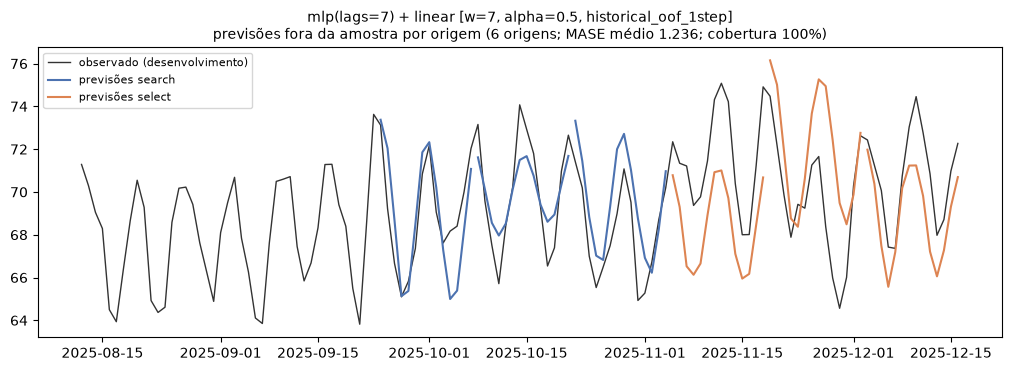

In [10]:
exp.plot_model(result.best, plot="cv_forecasts")

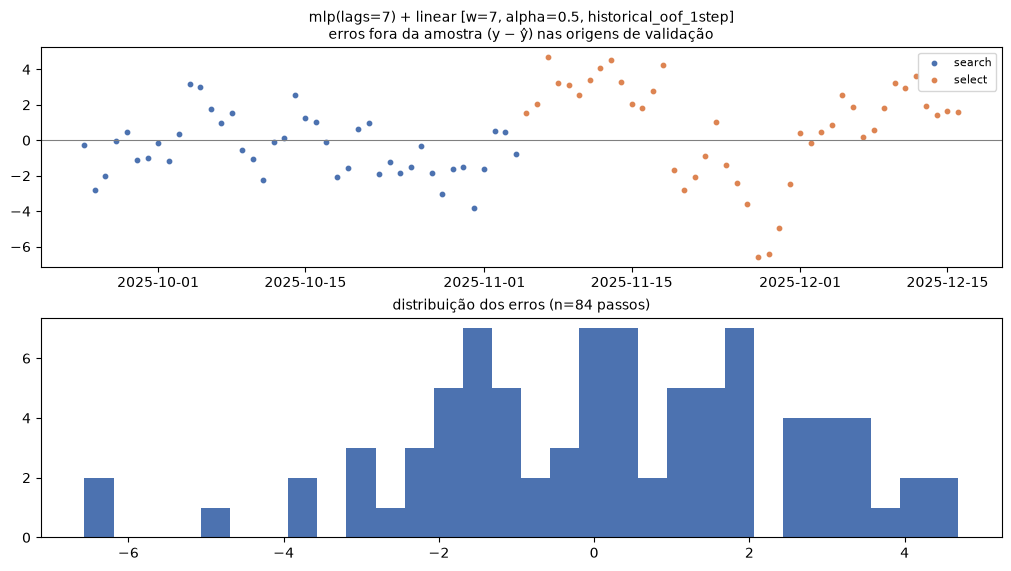

In [11]:
exp.plot_model(result.best, plot="residuals")

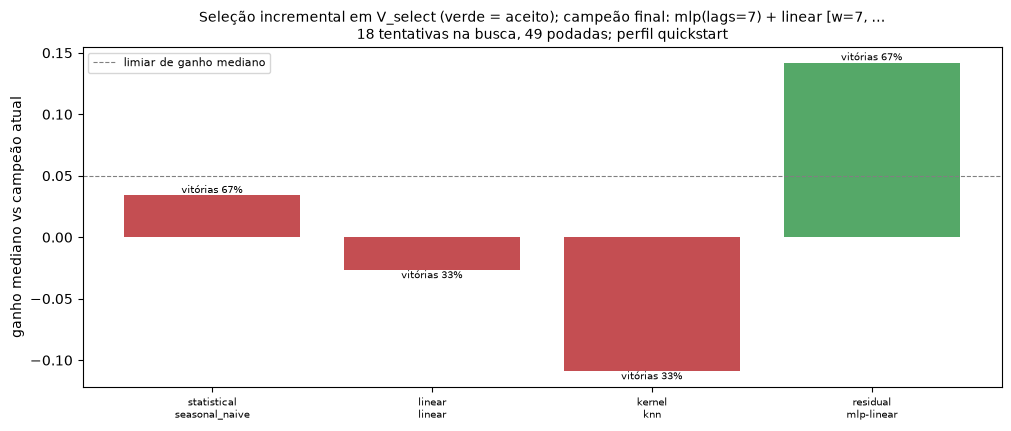

In [12]:
exp.plot_model(result.best, plot="selection_trace")

## 7. Experiment events

In [13]:
for event in exp.events:
    duration = f"{event.duration_ms:9.1f} ms" if event.duration_ms else " " * 12
    print(f"{event.kind:32s} {duration}  {event.message}")

experiment.fitted                     24.1 ms  1 série(s), 716 pontos de desenvolvimento, teste selado de 14 por série, 6 origens
model.created                      60436.4 ms  arima
hybrid.created                     50936.8 ms  arima + mlp [w=7, alpha=1.0, historical_oof_1step]
search.finished                    37496.5 ms  18 tentativas (budget_limited)
selection.finished                  5275.0 ms  champion: mlp(lags=7) + linear [w=7, alpha=0.5, historical_oof_1step]
